# WP12 — S04 tek istek hazırlığı

Bu notebook yalnız gerçek mevcut kaynak ve sayaçları inceler. S04 henüz **NOT_RUN**; token ve yanıt üretmez. S07 öncesi hazırlanmış soru, prompt, üç alıntı, bağlam ve şema aynıdır. Model kalitesine göre yöntem değişikliği yapılmadı.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S04_preparation_v1'
F=ROOT/'reports/figures/WP12/openai_S04_preparation_v1'
F.mkdir(parents=True,exist_ok=True)
read=lambda name: json.loads((Q/name).read_text(encoding='utf-8'))
display(pd.DataFrame([read('frozen_request_equivalence.json')]).T)

,0
frozen_file_sha256,1d00b04642bfec7081af0b9df8b782a20cd3208451cdf0e03afe60f052dc170a
canonical_request_sha256,79a1619390cc1e30a3f2b32c6b0b667a89e982fcf1c7c62381808c4d361e1a71
canonical_frozen_request_sha256,79a1619390cc1e30a3f2b32c6b0b667a89e982fcf1c7c62381808c4d361e1a71
request_object_identical,True
instructions_UTF8_identical,True
sources_and_question_identical,True
Structured_Outputs_schema_identical,True
request_transport_unchanged,True
initial_test_failure,File serialization newline comparison failed; parsed payload and UTF-8 prompt were unchanged. In...
new_model_method_or_prompt,False


**Yorum:** İstek nesnesi, UTF-8 prompt, kaynaklar ve şema eşit. İlk test dosya serileştirme/satır sonu farkını yöntem değişikliği sanmıştı; başarısız ilk kayıt saklandı, içerik ve taşıma biçimini ayrı sınayan test geçti.

In [2]:
sources=pd.read_csv(Q/'S04_source_dependencies.csv')
display(sources[['physical_page','char_start','char_end','characters','kind','qualifier','quote_id','context_count']])
for _,r in sources.iterrows():
    display(pd.DataFrame([{'fiziksel_sayfa':r.physical_page,'quote_ID':r.quote_id,'birebir_kaynak':r.quote,'zorunlu_bağlamlar':r.required_context_quote_ids}]))

,physical_page,char_start,char_end,characters,kind,qualifier,quote_id,context_count
0,4,1640,2087,447,adverse_section,Section4 starts here and continues on physical5,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,0
1,5,0,2371,2371,adverse_section,Continuation of section4;retain reporting/frequency context,quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85,1
2,5,825,1810,985,adverse_context,Frequency not known;no numeric probability,quote:a606c2c9f5d1862695ef31567790df3a34d34aae6ccdd088097c63f2bb6865d8,2


,fiziksel_sayfa,quote_ID,birebir_kaynak,zorunlu_bağlamlar
0,4,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468,"4. Possible side effects \n \nLike all medicines, this medicine can cause side effects, althoug...",[]


,fiziksel_sayfa,quote_ID,birebir_kaynak,zorunlu_bağlamlar
0,5,quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85,• diarrhoea which may be severe or prolonged and may contain blood or mucus \n• serious skin ras...,['quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468']


,fiziksel_sayfa,quote_ID,birebir_kaynak,zorunlu_bağlamlar
0,5,quote:a606c2c9f5d1862695ef31567790df3a34d34aae6ccdd088097c63f2bb6865d8,Other side effects of Erythromycin Tablets include-: \nNot known (frequency cannot be estimated ...,"['quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85', 'quote:b4d0701dab56bb..."


**Yorum:** Üç alıntı toplam 3803 karakterdir; örtüşen sayfa5/unknown bölümünü kesmedik. Bilinmeyen sıklık alıntısı sayfa5 ve sayfa4 bağlamını taşır. Doğru quote-ID, doğru Türkçe veya doğru anlam kanıtı değildir.

,durum,HTTP_reservations_total,inference_reservations_total,reserved_USD,within_limits,unknown_prior_cost_not_refunded,actual_invoice_total
0,Gerçek mevcut rezerv,9,3,0.069,True,True,UNKNOWN_NOT_QUERIED
1,S04 tamamlanırsa plan,12,4,0.092,True,True,UNKNOWN_NOT_QUERIED


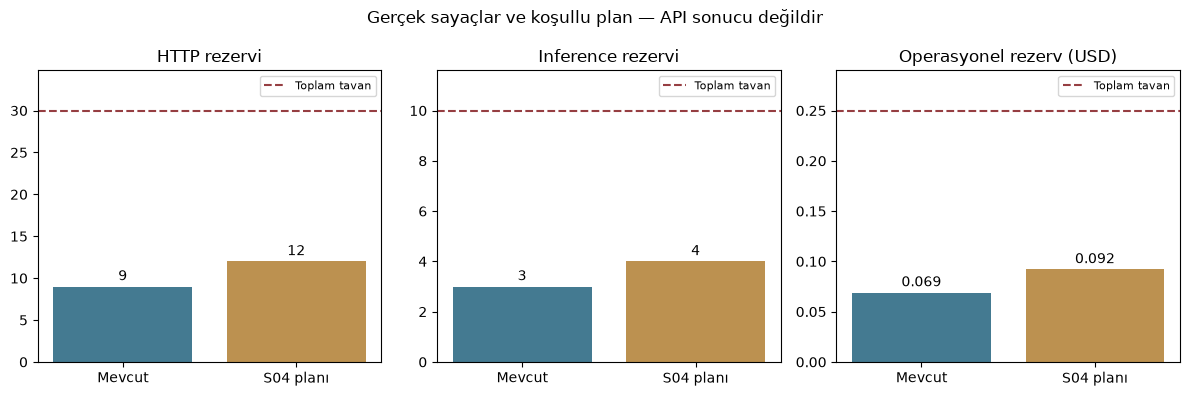

In [3]:
b=read('budget_before_and_projected.json')
table=pd.DataFrame([{'durum':label,**b[key]} for label,key in [('Gerçek mevcut rezerv','actual_reservations_before'),('S04 tamamlanırsa plan','planned_if_three_HTTP_and_one_inference_complete')]])
display(table)
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,col,cap,title in zip(axs,['HTTP_reservations_total','inference_reservations_total','reserved_USD'],[30,10,.25],['HTTP rezervi','Inference rezervi','Operasyonel rezerv (USD)']):
    vals=pd.to_numeric(table[col]);ax.bar(['Mevcut','S04 planı'],vals,color=['#447a91','#bc9150']);ax.axhline(cap,color='#963e42',linestyle='--',label='Toplam tavan');ax.set_title(title);ax.set_ylim(0,cap*1.16);ax.legend(fontsize=8)
    for i,v in enumerate(vals):ax.text(i,v+cap*.025,f'{v:g}',ha='center')
fig.suptitle('Gerçek sayaçlar ve koşullu plan — API sonucu değildir');plt.tight_layout();plt.savefig(F/'01_actual_reservations_and_conditional_plan.png',dpi=160);plt.show()

**Yorum:** Mevcut9HTTP/3inference/.069USD rezervi korunur. ÜçHTTP tamamlanırsa12/4/.092 olur. Bunlar gerçek fatura değildir; 429 dahil eski belirsiz maliyet iade varsayımıyla çıkarılmaz. Her çağrı bütçe/hash kontrolü yapar; inference öncesi exact server token sayımı zorunludur, bağlam kesilmez.

In [4]:
display(pd.DataFrame([read('test_summary.json'),read('PowerShell_parse_and_hash.json')]))
review=read('human_review_plan_S04.json')
display(pd.DataFrame({'önceden_dondurulmuş_inceleme_sorusu':review['frozen_plan']['required_review_questions_tr']}))
display(pd.DataFrame(review['dimensions_kept_separate']))
display(pd.DataFrame([read('S04_status_NOT_RUN.json')]))

,tests,returncode,new_API_requests,fixtures,initial_test_failure_preserved,errors,parser,executed,script_sha256,config_sha256,client_sha256
0,16.0,0.0,0.0,TEST_ONLY_NOT_MODEL_OUTPUT,True,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,0.0,PowerShell AST,False,511bf2f4166bf15851e2605acb63afe3b1a4b2d2e7d0272e68fa435f84ab2a1a,afad3cce7b13096b52ecafdbfa3b4088f33764f5ccb59a88a6886b81daae2208,97c47b04c63ed5f62c40697961cc668435b11d8963905e83d95c0b88595cd992


,önceden_dondurulmuş_inceleme_sorusu
0,Fiziksel4 başlangıcı ve fiziksel5 devam bağlamı korunuyor mu?
1,Not known ve frequency cannot be estimated anlamı açıkça korunuyor mu?
2,"Bilinmeyen sıklık sayısal olasılık, yaygınlık, sıfır risk veya kesin yokluk olarak yazılmış mı?"
3,Seçilen örneklerde may/usually/high doses/kidney problems gibi mevcut nitelemeler korunmuş mu?
4,"Prospektüsün acil başvuru/raporlama anlatımı, bağımsız kişisel tedavi tavsiyesine dönüşmüş mü?"


,dimension,review
0,Kaynak anlamı ve belirsizlik,Not known/cannot be estimated nitelemesi; uyarı/olasılık/koşullar; bilinmeyeni nadir/yaygın/yüzd...
1,Tam Türkçe açıklama,Gerçek cümleleri oku; language=tr beyanını başarı sayma. Kaynak ilaç/ürün adı ve birimler koruna...
2,Item düzeyinde atıf kapsamı,Her iddiayı birincil alıntı ve cite edilmiş bağlamlarla karşılaştır; doğru ID tek başına anlam d...
3,İnsan kararı ve yetki,Adlandırılmış inceleyici/rol/tarih/run-hash kapsamı ayrı olay kontrolündedir; Codex otomatik ona...


,scenario,execution,HTTP,tokens,cost_USD,technical_validation,agent_source_review,formal_human_review,automatic_publication
0,S04,NOT_RUN,NOT_RUN,None,None,NOT_RUN,NOT_RUN,PENDING,False


**Yorum:** 16 ağsız teknik test PASS, PowerShell yalnız parse edildi. İnceleyici bilinmeyen sıklığı, may/usually/koşulları, tam Türkçeyi ve item atıflarını ayrı değerlendirecek. İnsan kararı ayrı kimlik/rol/tarih/hash kapsamlı olayla yönetilir; burada otomatik onay/reddetme yoktur. S07 kullanıcı değerlendirmesi ayrı beyan olarak korundu; önceki QA değişmedi. WP13 yalnız kapsam belgesidir; uygulama başlamaz.